# Plot Link Landuse Grids

Generate plots of land use shares for study area data.

<br><br>

## 0. Setup

### 0.1. Imports and Config

In [1]:
import numpy as np
import pandas as pd

from splendor.config import SEED, STUDY_AREA, CORRIDOR_RADIUS, ROAD_STRIP_RADIUS
from splendor.io import load_network, load_raster
from splendor.landuse.corridors import get_link_corridors
from splendor.plotting.landuse import plot_link_landuse_grid
from splendor.plotting.style import set_math_font
from splendor.paths import (
    basemap05_main_types_path, 
    ensure_parent,
    landuse_path,
    landuse_plot_path,
    network_path
)

LEVEL = "links"
set_math_font()

### 0.2. Data

In [2]:
_, edges = load_network(network_path(STUDY_AREA))
edges = edges.sort_values("edge_id").reset_index(drop=True)
raster, transform, _ = load_raster(basemap05_main_types_path(STUDY_AREA))
shares = pd.read_csv(landuse_path(STUDY_AREA, LEVEL, CORRIDOR_RADIUS, ROAD_STRIP_RADIUS)).set_index("edge_id")
corridors = get_link_corridors(edges, CORRIDOR_RADIUS)

<br><br>

## 1. Random Links

### 1.1. Config

In [3]:
N_COLS = 4

### 1.2. Plot

Saved /Users/sanderengelthilo/dev/bikenwsplendor/plots/pilot/link_landuse_random_r100.png


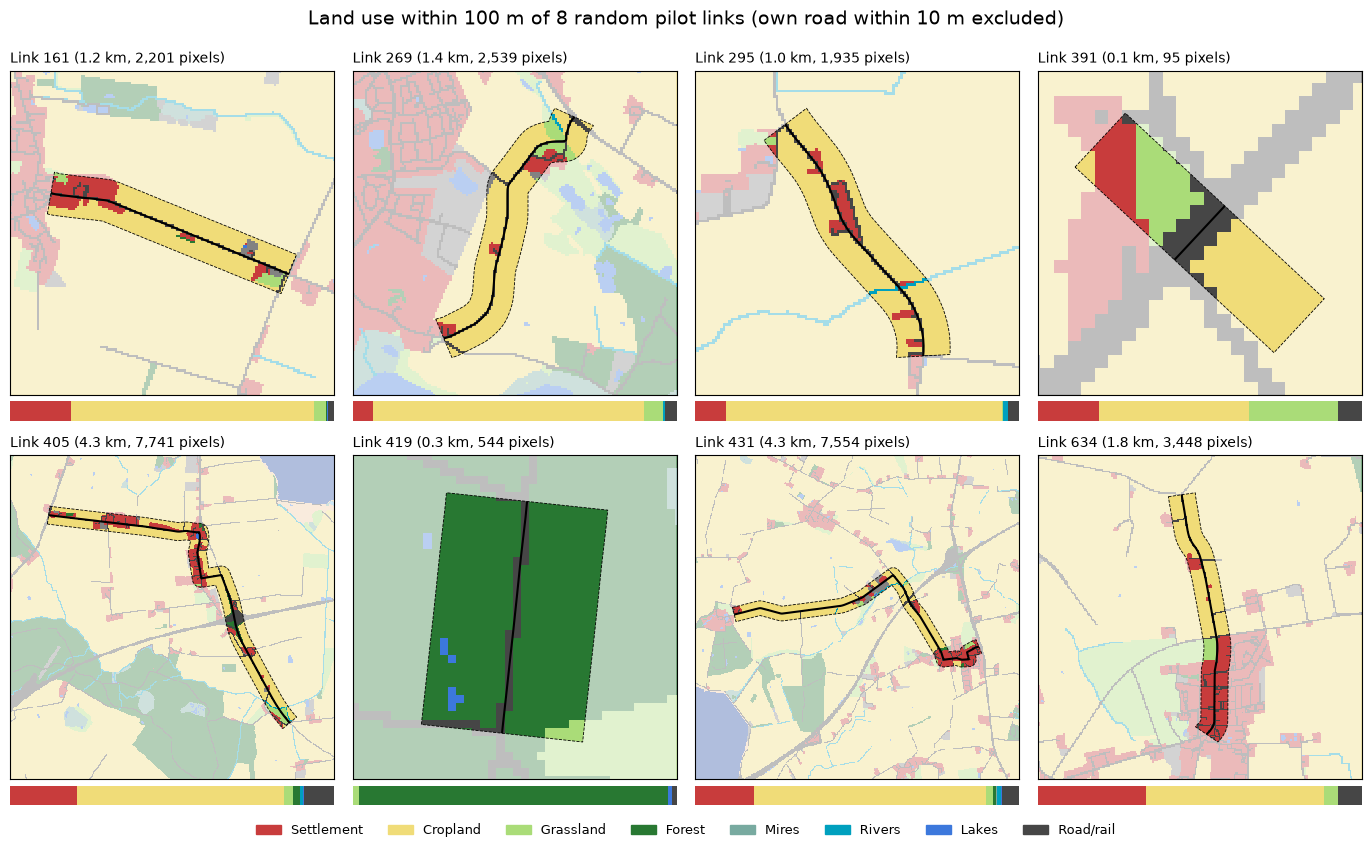

In [4]:
n_rows = 2
n_links = n_rows * N_COLS

detail = "random"
out = landuse_plot_path(STUDY_AREA, LEVEL, CORRIDOR_RADIUS, detail)


rng = np.random.default_rng(SEED)
edge_ids = np.sort(rng.choice(len(edges), size=n_links, replace=False))

fig = plot_link_landuse_grid(
    edge_ids, edges, corridors, shares, raster, transform,
    n_cols=N_COLS, 
    title=f"Land use within {CORRIDOR_RADIUS} m of {n_links} {detail} {STUDY_AREA} links "
    f"(own road within 10 m excluded)" 
)
fig.savefig(ensure_parent(out), dpi=150)
print(f"Saved {out}")

Saved /Users/sanderengelthilo/dev/bikenwsplendor/plots/pilot/link_landuse_random_report_r100.png


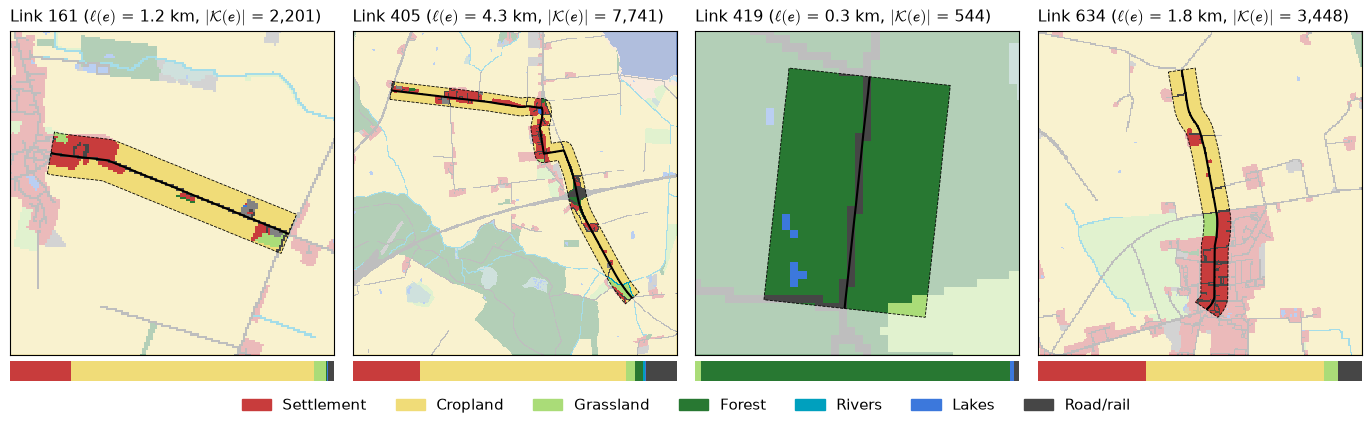

In [5]:
# Specifically for the report
edge_ids = [161, 405, 419, 634]

n_rows = 1
n_links = n_rows * N_COLS

detail = "random_report"
out = landuse_plot_path(STUDY_AREA, LEVEL, CORRIDOR_RADIUS, detail)

fig = plot_link_landuse_grid(
    edge_ids, edges, corridors, shares, raster, transform,
    n_cols=N_COLS, 
    symbol='e',
    fontsize=11.5
)
fig.savefig(ensure_parent(out), dpi=150)
print(f"Saved {out}")